# Week 1 Assessment – Employee Data Analysis

## 1. Introduction

This notebook analyses employee data using Python, Pandas, NumPy, and Matplotlib.

### Objectives
- Load and inspect employee data.
- Clean missing values.
- Analyse salaries by department.
- Create visualisations.
- Measure performance using `%timeit`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load employee data
df = pd.read_csv("../data/employees2.csv")

# Display the first five rows
df.head()

,id,name,department,age,salary
0,1,Alice,Sales,25,60000.0
1,2,Bob,Sales,28,45000.0
2,3,Charlie,HR,30,52000.0
3,4,David,HR,35,NaN
4,5,Emma,IT,24,70000.0


In [4]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Generate statistical summary
df.describe()

Dataset shape: (8, 5)
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          8 non-null      int64  
 1   name        8 non-null      str    
 2   department  8 non-null      str    
 3   age         8 non-null      int64  
 4   salary      6 non-null      float64
dtypes: float64(1), int64(2), str(2)
memory usage: 452.0 bytes


,id,age,salary
count,8.00000,8.00000,6.000000
mean,4.50000,30.37500,56666.666667
std,2.44949,5.26274,9912.954487
min,1.00000,24.00000,45000.000000
25%,2.75000,27.25000,49000.000000
50%,4.50000,29.50000,56000.000000
75%,6.25000,32.75000,63750.000000
max,8.00000,40.00000,70000.000000


In [5]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Calculate median salary
median_salary = df["salary"].median()

# Fill missing salaries with median
df["salary"] = df["salary"].fillna(median_salary)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Display cleaned data
df

Missing values before cleaning:
id            0
name          0
department    0
age           0
salary        2
dtype: int64

Missing values after cleaning:
id            0
name          0
department    0
age           0
salary        0
dtype: int64


,id,name,department,age,salary
0,1,Alice,Sales,25,60000.0
1,2,Bob,Sales,28,45000.0
2,3,Charlie,HR,30,52000.0
3,4,David,HR,35,56000.0
4,5,Emma,IT,24,70000.0
5,6,Frank,IT,29,56000.0
6,7,Grace,IT,32,65000.0
7,8,Henry,Finance,40,48000.0


In [6]:
# Calculate department-wise salary statistics
department_analysis = df.groupby("department")["salary"].agg(
    employee_count="count",
    average_salary="mean",
    maximum_salary="max",
    minimum_salary="min"
)

# Display results
print(department_analysis)

            employee_count  average_salary  maximum_salary  minimum_salary
department                                                                
Finance                  1    48000.000000         48000.0         48000.0
HR                       2    54000.000000         56000.0         52000.0
IT                       3    63666.666667         70000.0         56000.0
Sales                    2    52500.000000         60000.0         45000.0


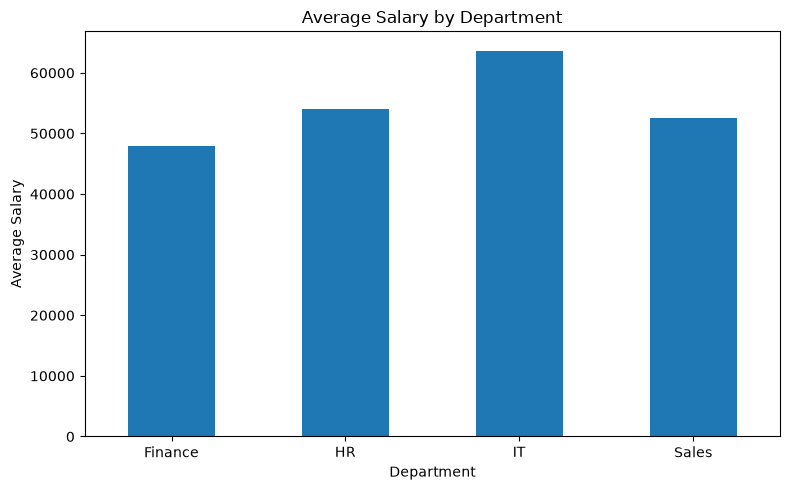

In [7]:
# Calculate average salary by department
avg_salary = df.groupby("department")["salary"].mean()

# Create bar chart
plt.figure(figsize=(8, 5))
avg_salary.plot(kind="bar")

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

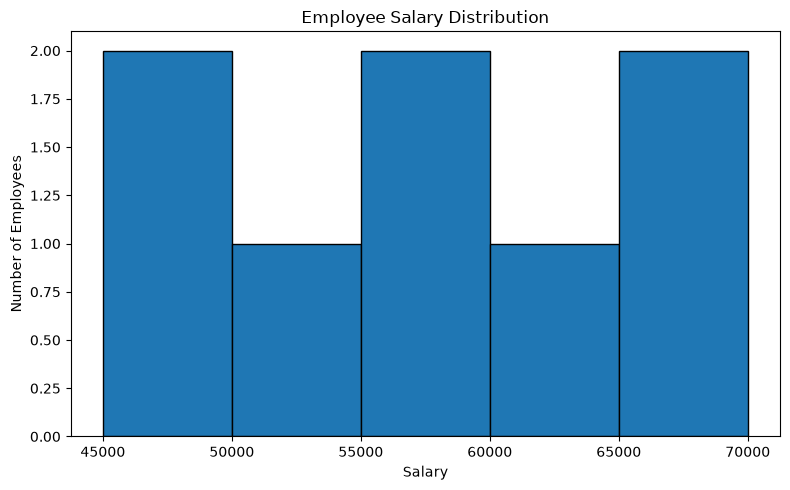

In [8]:
# Create salary histogram
plt.figure(figsize=(8, 5))

plt.hist(df["salary"], bins=5, edgecolor="black")

plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

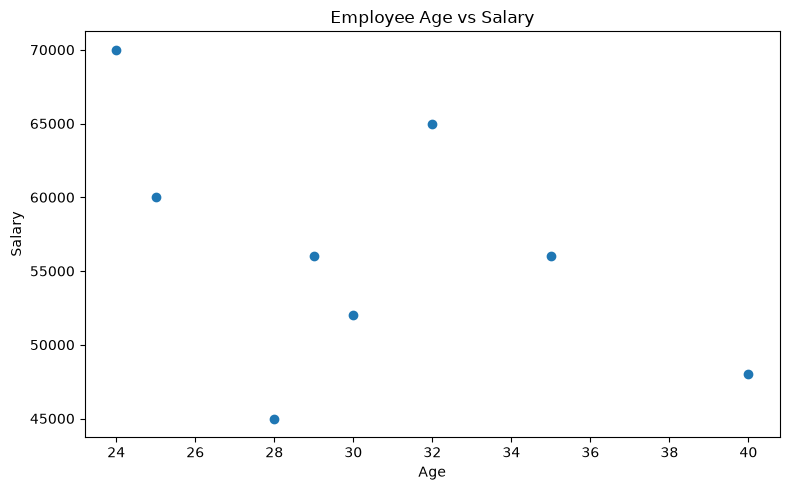

In [9]:
# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(df["age"], df["salary"])

plt.title("Employee Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.tight_layout()
plt.show()

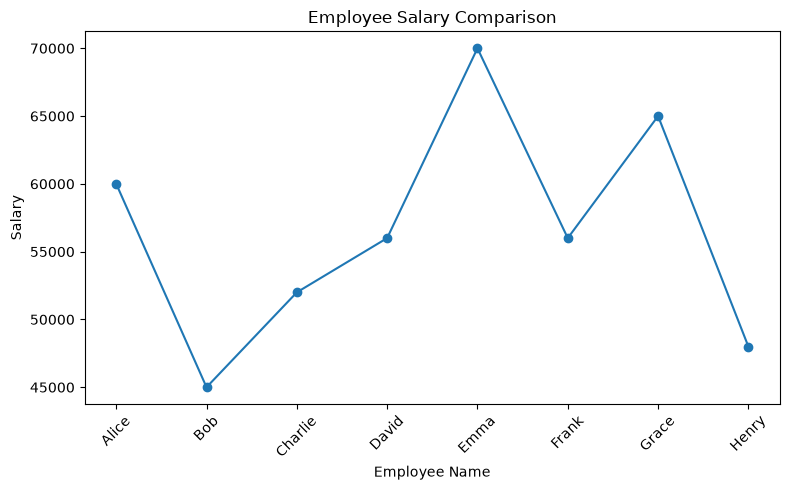

In [10]:
# Create line chart
plt.figure(figsize=(8, 5))

plt.plot(df["name"], df["salary"], marker="o")

plt.title("Employee Salary Comparison")
plt.xlabel("Employee Name")
plt.ylabel("Salary")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
## 12. Key Findings and Conclusion

1. The dataset contains 8 employees across 4 departments.
2. Two missing salary values were identified and replaced with the median salary of 56,000.
3. The IT department has the highest average salary.
4. The Finance department has the lowest average salary.
5. The charts show salary variation across departments and employees. Age alone does not explain salary differences.

### Conclusion

The employee dataset was successfully loaded, cleaned, analysed, and visualised using Pandas, NumPy, and Matplotlib. The `%timeit` command was used to measure the performance of the department-wise salary calculation.

In [11]:
%timeit df.groupby("department")["salary"].mean()

331 μs ± 45.6 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
